# DeepPCB: Explainable Visual Inspection on a CPU
### Defect localisation, six-class recognition, and robustness to camera misalignment

**Course:** Computer Vision for AI · **Student:** Shashwat Jain  
**Dataset:** [DeepPCB by Tang et al.](https://github.com/tangsanli5201/DeepPCB)  
**Implementation:** developed with OpenAI Codex assistance; review and understand the implementation before presenting it.

This notebook implements an original educational pipeline using OpenCV and scikit-learn.
**No PyTorch, GPU, YOLO weights, or hidden pretrained model is required.**
The dataset name “DeepPCB” does not mean that every method using it must be deep learning.

**Research question:** Can reference-image comparison and handcrafted features detect and classify PCB defects,
and how much does feature-based registration recover performance when the camera moves?

**Roadmap:** setup → data audit → exploratory visuals → validation split → proposals → HOG classifier →
held-out detection metrics → alignment stress test → failure analysis → reusable inference.

> Dataset images contain artificially added defects and are already aligned and binarised.
> This is a research prototype, not a validated factory inspection system.

## 1. Setup and reproducibility
Use Python 3.12 (tested), or a compatible Python 3.10+ installation. Run the next cell once in a fresh environment.
It uses the current notebook kernel. Existing compatible packages are retained.
Then choose **Run All**. The full workflow downloads the data if absent, trains on CPU, and writes results.
The dataset is pinned to a source revision; outputs may vary slightly with library versions and hardware.

In [ ]:
%pip install "numpy>=1.26,<3" "pandas>=2.2,<4" "opencv-python-headless==4.11.0.86" "scikit-learn>=1.5,<2" "matplotlib>=3.9,<4" "joblib>=1.4,<2"

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import subprocess
import time
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import joblib

SEED = 42
SOURCE_COMMIT = '08e98c4db5922613fb97176eb3d6497d48260cb1'
CLASSES = {0: 'background', 1: 'open', 2: 'short', 3: 'mousebite',
           4: 'spur', 5: 'spurious copper', 6: 'pin hole'}
COLORS = ['#64748b', '#ef4444', '#f59e0b', '#22c55e', '#06b6d4', '#a855f7', '#ec4899']
cv2.setNumThreads(2)
cv2.setRNGSeed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

In [2]:
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
ARTIFACTS = ROOT / 'artifacts'
ARTIFACTS.mkdir(exist_ok=True)
versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'opencv': cv2.__version__}
import sklearn, matplotlib
versions.update(sklearn=sklearn.__version__, matplotlib=matplotlib.__version__)
print('Runtime:', versions)
print('CPU only; random seed:', SEED)

Runtime: {'python': '3.12.14', 'numpy': '2.5.4', 'pandas': '3.0.1', 'opencv': '4.11.0', 'sklearn': '1.9.1', 'matplotlib': '3.11.2'}
CPU only; random seed: 42


## 2. Download, validate, and understand the data
DeepPCB provides **1,500 image pairs** and six defect categories. The official split is 1,000 training/validation
pairs and 500 test pairs. Each pair contains a clean reference and inspected board, both 640 × 640 pixels.
The original split files mention a base `.jpg`; the actual images use `_temp.jpg` and `_test.jpg` suffixes.

Labels contain `x1 y1 x2 y2 class_id`. This implementation uses a consistent continuous/half-open box convention
for width, height and IoU (no `+1` area correction). Read the upstream description before comparing scores.

| ID | Defect | Interpretation |
|---|---|---|
| 1 | Open | Interrupted conducting path |
| 2 | Short | Unwanted bridge between paths |
| 3 | Mousebite | Notch in a track edge |
| 4 | Spur | Protrusion from a track |
| 5 | Spurious copper | Isolated unwanted material |
| 6 | Pin hole | Hole inside a conducting region |

The upstream README restricts the **dataset to research use**. Raw images are downloaded locally and excluded
from this repository. Visual examples derived from them are credited in the figures and CREDITS.md.

In [3]:
def ensure_dataset(root):
    """Download the pinned upstream archive once; never publish raw data."""
    root = Path(root)
    target = root / 'data' / 'DeepPCB'
    if (target / 'PCBData' / 'trainval.txt').exists():
        if (target / '.git').exists():
            actual = subprocess.check_output(
                ['git', '-C', str(target), 'rev-parse', 'HEAD'], text=True).strip()
            if actual != SOURCE_COMMIT:
                raise ValueError(f'Dataset revision {actual} differs from pinned {SOURCE_COMMIT}')
        return target / 'PCBData'
    target.parent.mkdir(parents=True, exist_ok=True)
    archive = target.parent / 'DeepPCB-pinned.zip'
    url = f'https://codeload.github.com/tangsanli5201/DeepPCB/zip/{SOURCE_COMMIT}'
    print('Downloading official DeepPCB archive (research use only)...')
    urllib.request.urlretrieve(url, archive)
    prefix = f'DeepPCB-{SOURCE_COMMIT}/'
    with zipfile.ZipFile(archive) as z:
        for entry in z.infolist():
            if not entry.filename.startswith(prefix) or entry.is_dir():
                continue
            relative = Path(entry.filename[len(prefix):])
            dest = (target / relative).resolve()
            if not dest.is_relative_to(target.resolve()):
                raise ValueError('Unsafe archive path')
            dest.parent.mkdir(parents=True, exist_ok=True)
            dest.write_bytes(z.read(entry))
    (target / 'SOURCE_COMMIT').write_text(SOURCE_COMMIT)
    return target / 'PCBData'


def read_split(data_dir, name):
    records = []
    for line in (data_dir / f'{name}.txt').read_text().splitlines():
        image_rel, label_rel = line.split()
        base = data_dir / image_rel
        rec = dict(id=base.stem, group=Path(image_rel).parts[0],
                   test=str(base.with_name(base.stem + '_test.jpg')),
                   template=str(base.with_name(base.stem + '_temp.jpg')),
                   annotation=str(data_dir / label_rel))
        for key in ['test', 'template', 'annotation']:
            if not Path(rec[key]).is_file():
                raise FileNotFoundError(rec[key])
        records.append(rec)
    return records


def load_pair(rec):
    template = cv2.imread(rec['template'], cv2.IMREAD_GRAYSCALE)
    tested = cv2.imread(rec['test'], cv2.IMREAD_GRAYSCALE)
    if template is None or tested is None or template.shape != tested.shape:
        raise ValueError(f'Invalid image pair: {rec["id"]}')
    return template, tested


def ground_truth(rec):
    a = np.loadtxt(rec['annotation'], dtype=int, ndmin=2)
    if a.shape[1] != 5 or not np.isin(a[:, 4], list(range(1, 7))).all():
        raise ValueError(f'Invalid annotation: {rec["id"]}')
    return a


def audit_dataset(trainval, test):
    assert len(trainval) == 1000 and len(test) == 500
    assert len({r['id'] for r in trainval + test}) == 1500
    rows, hashes = [], {}
    for split, records in [('trainval', trainval), ('test', test)]:
        for rec in records:
            template, tested = load_pair(rec)
            assert tested.shape == (640, 640)
            gt = ground_truth(rec)
            assert (gt[:, :2] >= 0).all() and (gt[:, 2:4] <= 640).all()
            assert (gt[:, 2:4] > gt[:, :2]).all()
            digest = hashlib.sha256(tested.tobytes()).hexdigest()
            if digest in hashes and hashes[digest] != split:
                raise AssertionError('Exact tested-image duplicate across official splits')
            hashes[digest] = split
            for box in gt:
                rows.append(dict(split=split, image=rec['id'], group=rec['group'],
                                 class_id=int(box[4]), defect=CLASSES[int(box[4])],
                                 width=int(box[2]-box[0]), height=int(box[3]-box[1])))
    return pd.DataFrame(rows)


def split_training(trainval):
    """Image-disjoint validation, stratified by source group; NOT layout-disjoint."""
    train, val = train_test_split(trainval, test_size=0.2, random_state=SEED,
                                 stratify=[r['group'] for r in trainval])
    return sorted(train, key=lambda r:r['id']), sorted(val, key=lambda r:r['id'])

In [4]:
DATA_DIR = ensure_dataset(ROOT)
trainval = read_split(DATA_DIR, 'trainval')
test = read_split(DATA_DIR, 'test')
inventory = audit_dataset(trainval, test)
train, val = split_training(trainval)
assert not ({r['id'] for r in train} & {r['id'] for r in val})
assert not ({r['id'] for r in trainval} & {r['id'] for r in test})
manifest = {'source_commit': SOURCE_COMMIT, 'seed': SEED,
            'train': [r['id'] for r in train], 'validation': [r['id'] for r in val],
            'test': [r['id'] for r in test]}
(ARTIFACTS / 'split_manifest.json').write_text(json.dumps(manifest, indent=2))
print(f'Audited {len(trainval)+len(test)} image pairs and {len(inventory)} labelled defects.')
print(f'Train: {len(train)} | Validation: {len(val)} | Test: {len(test)}')
display(inventory.groupby(['split', 'defect']).size().unstack(fill_value=0))

Audited 1500 image pairs and 10013 labelled defects.
Train: 800 | Validation: 200 | Test: 500


defect,mousebite,open,pin hole,short,spur,spurious copper
split,,,,,,
test,586,659,470,478,483,464
trainval,1379,1283,1031,1028,1142,1010


### Split discipline and limitations
- Training: 800 images; validation: 200 images; official test: 500 images.
- Split before extracting crops. All crops from one image remain in the same split.
- The validation split is stratified by upstream source group, **not group-disjoint**.
- Source layouts may be shared across official partitions. Exact tested-image duplicates are checked, but
  passing this check does not rule out related layouts or near duplicates.
- Hyperparameters and confidence thresholds use validation only. Test labels are used for audit,
  final evaluation and post-hoc error analysis, never feature extraction or inference.
- An unseen-layout claim would require a separate group-held-out experiment.

### Development transparency
The initial baseline was evaluated on the official test set and exposed low recall. Inspection of a **training**
pair and validation proposal recall motivated adding morphological opening to suppress thin boundary artifacts.
The opening radius and other settings are selected on validation only. Initial results are preserved in
`artifacts/initial_baseline_results.json`. Because the official test was already observed during development,
the final result is a **reused benchmark evaluation**, not a pristine one-shot estimate of generalisation.
A new independent dataset would be needed for that stronger claim.

## 3. Exploratory analysis and visual inspection
Inspect an actual image pair, class frequencies and defect sizes before selecting methods.
Tiny defects and repeated circuit patterns motivate local geometry features and careful image registration.

In [5]:
def save_figure(fig, root, filename):
    directory = Path(root) / 'assets'
    directory.mkdir(exist_ok=True)
    fig.savefig(directory / filename, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)


def draw_boxes(ax, image, boxes, labels, title, scores=None):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    for i, (box, label) in enumerate(zip(boxes, labels)):
        x1,y1,x2,y2 = box
        color = COLORS[int(label)]
        ax.add_patch(Rectangle((x1,y1), x2-x1, y2-y1, fill=False, edgecolor=color, linewidth=1.5))
        caption = CLASSES[int(label)]
        if scores is not None:
            caption += f' {scores[i]:.2f}'
        ax.text(x1, max(y1-3, 8), caption, color='white', fontsize=7,
                bbox=dict(facecolor=color, alpha=.85, edgecolor='none', pad=1))
    ax.set_title(title); ax.axis('off')


def show_pair(rec, root):
    t, s = load_pair(rec); gt = ground_truth(rec)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(t, cmap='gray'); axes[0].axis('off'); axes[0].set_title('Defect-free template')
    draw_boxes(axes[1], s, gt[:,:4], gt[:,4], 'Inspected board: ground truth')
    axes[2].imshow(cv2.absdiff(t,s), cmap='inferno'); axes[2].axis('off'); axes[2].set_title('Absolute difference')
    fig.suptitle(f'DeepPCB pair {rec["id"]} | Source: Tang et al., DeepPCB', fontsize=13)
    fig.tight_layout(); save_figure(fig, root, '01_dataset_pair.png')


def show_predictions(rec, predictions, root, filename='05_predictions.png'):
    t, s = load_pair(rec); gt = ground_truth(rec)
    pp = predictions[rec['id']]
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    draw_boxes(axes[0], s, gt[:,:4], gt[:,4], 'Ground truth')
    draw_boxes(axes[1], s, [p['box'] for p in pp], [p['label'] for p in pp],
               'Predictions (no labels used at inference)', [p['score'] for p in pp])
    fig.suptitle(f'Test image {rec["id"]} | Source imagery: DeepPCB'); fig.tight_layout()
    save_figure(fig, root, filename)


def inspect_custom(template_path, tested_path, model, config, threshold, method='ORB'):
    """Inference accepts only images, no annotation file; returns boxes in template coordinates."""
    t = cv2.imread(str(template_path), cv2.IMREAD_GRAYSCALE)
    s = cv2.imread(str(tested_path), cv2.IMREAD_GRAYSCALE)
    if t is None or s is None or t.shape != s.shape:
        raise ValueError('Provide readable, equally sized grayscale-compatible image pairs.')
    aligned, valid, info = register_pair(t, s, method)
    if not info['success']:
        return dict(status='registration_failed', reason=info['reason'], predictions=[])
    predictions = detect(t, aligned, model, config, threshold, valid)
    return dict(status='ok', coordinate_frame='template', predictions=predictions,
                aligned=aligned, metadata=info)

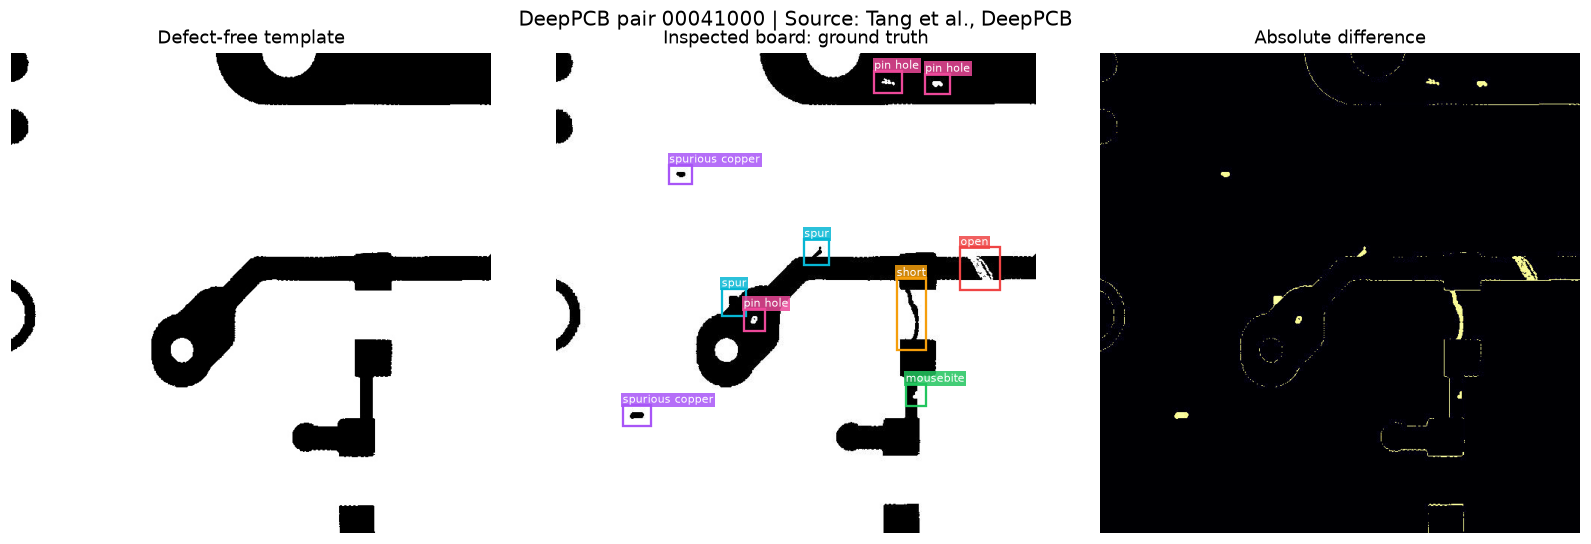

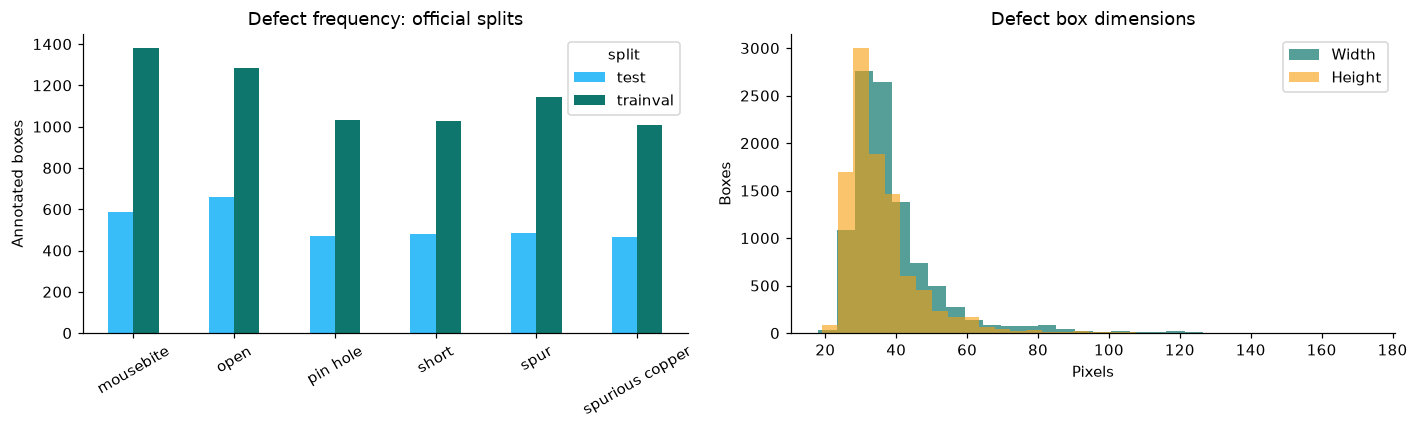

In [6]:
show_pair(train[0], ROOT)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = inventory.groupby(['defect','split']).size().unstack(fill_value=0)
counts.plot.bar(ax=axes[0], color=['#38bdf8','#0f766e'])
axes[0].set(title='Defect frequency: official splits', ylabel='Annotated boxes', xlabel='')
axes[0].tick_params(axis='x', rotation=30)
axes[1].hist(inventory.width, bins=30, alpha=.7, label='Width', color='#0f766e')
axes[1].hist(inventory.height, bins=30, alpha=.6, label='Height', color='#f59e0b')
axes[1].set(title='Defect box dimensions', xlabel='Pixels', ylabel='Boxes'); axes[1].legend()
fig.tight_layout(); save_figure(fig, ROOT, '02_dataset_statistics.png')

## 4. Classical defect proposals
1. Threshold both grayscale images at 127 (appropriate for this already binarised dataset).
2. Compute pixel disagreement: `template_binary XOR inspected_binary`.
3. Optionally apply morphological opening to remove thin edge artifacts, then dilate to connect defect pieces.
4. Find connected components; remove tiny components by original changed-pixel area.
5. Pad each component to provide local context and a bounding box.

This step is **class-agnostic**. It does not read annotations. Threshold 127, padding 9, feature sizes and model
structure are fixed design choices; the small proposal search and classification threshold use validation.
Proposal recall asks whether each real defect has *any* candidate with IoU ≥ 0.50; it is an upper bound,
not a full detector score (one candidate can cover multiple annotations in this diagnostic).

In [7]:
def box_iou(a, b):
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    low = np.maximum(a[:, None, :2], b[None, :, :2])
    high = np.minimum(a[:, None, 2:], b[None, :, 2:])
    intersection = np.maximum(high-low, 0).prod(axis=2)
    aa = np.maximum(a[:, 2:]-a[:, :2], 0).prod(axis=1)
    bb = np.maximum(b[:, 2:]-b[:, :2], 0).prod(axis=1)
    return intersection / np.maximum(aa[:, None] + bb[None, :] - intersection, 1e-9)


def propose(template, tested, min_area=8, dilation=1, pad=9, opening=0, valid=None):
    """Binary disagreement -> morphology -> components -> padded xyxy boxes."""
    t = template > 127
    s = tested > 127
    diff = (t != s).astype(np.uint8)
    if valid is not None:
        diff[~valid] = 0
    if opening:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*opening+1, 2*opening+1))
        diff = cv2.morphologyEx(diff, cv2.MORPH_OPEN, kernel)
    mask = cv2.dilate(diff, np.ones((2*dilation+1, 2*dilation+1), np.uint8))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    boxes = []
    h, w = tested.shape
    for idx in range(1, n):
        x, y, bw, bh, _ = stats[idx]
        actual_area = int(diff[y:y+bh, x:x+bw][labels[y:y+bh, x:x+bw] == idx].sum())
        if actual_area < min_area:
            continue
        boxes.append([max(0, x-pad), max(0, y-pad),
                      min(w, x+bw+pad), min(h, y+bh+pad)])
    return np.asarray(boxes, dtype=int).reshape(-1, 4), diff, mask


HOG = cv2.HOGDescriptor((32, 32), (16, 16), (8, 8), (8, 8), 9)


def describe(template, tested, box):
    """HOG captures local geometry; signed changes distinguish missing/extra material."""
    x1, y1, x2, y2 = np.asarray(box, int)
    h, w = template.shape
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)
    t = template[y1:y2, x1:x2]
    s = tested[y1:y2, x1:x2]
    if not t.size:
        raise ValueError('Empty feature crop')
    tb, sb = t > 127, s > 127
    plus, minus = sb & ~tb, tb & ~sb
    channels = [t, s, (tb != sb).astype(np.uint8)*255]
    hog = [HOG.compute(cv2.resize(ch, (32, 32))).ravel() for ch in channels]
    signed_grid = [cv2.resize(ch.astype(np.float32), (8, 8),
                              interpolation=cv2.INTER_AREA).ravel() for ch in [plus, minus]]
    geom = [np.log1p(x2-x1), np.log1p(y2-y1), (x2-x1)/(y2-y1),
            tb.mean(), sb.mean(), plus.mean(), minus.mean()]
    return np.concatenate(hog + signed_grid + [geom]).astype(np.float32)


def make_training_data(records, config):
    """Only training images; proposal labels assigned by IoU, never at inference."""
    rng = np.random.default_rng(SEED)
    xx, yy = [], []
    for rec in records:
        t, s = load_pair(rec)
        gt = ground_truth(rec)
        boxes, _, _ = propose(t, s, **config)
        if len(boxes):
            overlaps = box_iou(boxes, gt[:, :4])
            for box, overlap in zip(boxes, overlaps):
                j = int(overlap.argmax())
                label = int(gt[j, 4]) if overlap[j] >= 0.33 else 0
                xx.append(describe(t, s, box)); yy.append(label)
        # Ground-truth crops with small box jitter teach proposal-boundary tolerance.
        for row in gt:
            b = row[:4].copy()
            b += rng.integers(-3, 4, size=4)
            b[:2] = np.maximum(b[:2], 0); b[2:] = np.minimum(b[2:], 640)
            if np.all(b[2:] > b[:2]):
                xx.append(describe(t, s, b)); yy.append(int(row[4]))
        for _ in range(2):
            x, y = rng.integers(0, 596, size=2)
            b = [x, y, x+44, y+44]
            if box_iou([b], gt[:, :4]).max() < 0.05:
                xx.append(describe(t, s, b)); yy.append(0)
    return np.asarray(xx), np.asarray(yy)


def fit_classifier(x, y):
    model = RandomForestClassifier(n_estimators=160, max_features='sqrt',
                                   min_samples_leaf=2, class_weight='balanced_subsample',
                                   random_state=SEED, n_jobs=2)
    return model.fit(x, y)


def detect(template, tested, model, config, threshold=0.35, valid=None):
    boxes, _, _ = propose(template, tested, valid=valid, **config)
    if len(boxes) == 0:
        return []
    features = np.stack([describe(template, tested, b) for b in boxes])
    probability = model.predict_proba(features)
    labels = model.classes_[probability.argmax(axis=1)]
    confidence = probability.max(axis=1)
    return [dict(box=b.tolist(), label=int(c), score=float(p))
            for b, c, p in zip(boxes, labels, confidence) if c != 0 and p >= threshold]

In [8]:
def match_predictions(predictions, gt, iou_threshold=0.5, class_aware=True):
    """Confidence-ordered one-to-one assignment; duplicate detections are false positives."""
    used, outcomes = set(), []
    for pred in sorted(predictions, key=lambda p: -p['score']):
        overlaps = box_iou([pred['box']], gt[:, :4])[0]
        eligible = [j for j in range(len(gt)) if j not in used
                    and (not class_aware or gt[j, 4] == pred['label'])]
        best = max(eligible, key=lambda j: overlaps[j], default=None)
        ok = best is not None and overlaps[best] >= iou_threshold
        if ok:
            used.add(best)
        outcomes.append((pred, bool(ok)))
    return outcomes, used


def score_predictions(records, predictions, iou_threshold=0.5):
    gt_by_id = {r['id']: ground_truth(r) for r in records}
    rows = []
    for c in range(1, 7):
        entries, count = [], 0
        for rec in records:
            gt = gt_by_id[rec['id']]
            gt = gt[gt[:, 4] == c]
            count += len(gt)
            pp = [p for p in predictions[rec['id']] if p['label'] == c]
            outcomes, _ = match_predictions(pp, gt, iou_threshold)
            entries.extend((p['score'], ok) for p, ok in outcomes)
        entries.sort(key=lambda x: -x[0])
        tp = np.cumsum([int(x[1]) for x in entries], dtype=float)
        fp = np.cumsum([int(not x[1]) for x in entries], dtype=float)
        recall = tp / max(count, 1)
        precision = tp / np.maximum(tp+fp, 1)
        # All-point interpolated AP (not COCO's 101-point / multi-IoU AP).
        mr = np.r_[0., recall, 1.]
        mp = np.r_[0., precision, 0.]
        mp = np.maximum.accumulate(mp[::-1])[::-1]
        indices = np.where(mr[1:] != mr[:-1])[0]
        ap = float(np.sum((mr[indices+1]-mr[indices])*mp[indices+1]))
        ntp = int(tp[-1]) if len(tp) else 0
        nfp = len(entries)-ntp
        nfn = count-ntp
        p, r = ntp/max(ntp+nfp, 1), ntp/max(count, 1)
        rows.append(dict(defect=CLASSES[c], class_id=c, ground_truth=count,
                         TP=ntp, FP=nfp, FN=nfn, precision=p, recall=r,
                         F1=2*p*r/max(p+r, 1e-9), AP=ap))
    frame = pd.DataFrame(rows)
    ntp, nfp, nfn = (int(frame[k].sum()) for k in ['TP', 'FP', 'FN'])
    p, r = ntp/max(ntp+nfp, 1), ntp/max(ntp+nfn, 1)
    summary = dict(IoU=iou_threshold, precision=p, recall=r,
                   F1=2*p*r/max(p+r, 1e-9), mAP=float(frame.AP.mean()),
                   TP=ntp, FP=nfp, FN=nfn, images=len(records))
    return frame, summary


def predict_records(records, model, config, threshold=0.):
    start = time.perf_counter()
    predictions = {}
    for rec in records:
        t, s = load_pair(rec)
        predictions[rec['id']] = detect(t, s, model, config, threshold)
    return predictions, time.perf_counter()-start


def threshold_predictions(predictions, threshold):
    return {k: [p for p in values if p['score'] >= threshold]
            for k, values in predictions.items()}


def proposal_recall(records, config):
    found, total, candidates = 0, 0, 0
    for rec in records:
        t, s = load_pair(rec)
        boxes, _, _ = propose(t, s, **config)
        gt = ground_truth(rec)
        total += len(gt); candidates += len(boxes)
        if len(boxes):
            found += int((box_iou(boxes, gt[:, :4]).max(axis=0) >= .5).sum())
    return dict(**config, recall_at_50=found/total,
                proposals_per_image=candidates/len(records))

,min_area,dilation,pad,opening,recall_at_50,proposals_per_image
5,8,1,9,1,0.952941,18.545
1,4,1,9,1,0.952941,22.415
9,16,1,9,1,0.949265,15.175
7,8,2,9,1,0.943382,16.070
3,4,2,9,1,0.943382,18.670
11,16,2,9,1,0.938971,13.710
8,16,1,9,0,0.629412,56.595
4,8,1,9,0,0.629412,81.735
0,4,1,9,0,0.629412,113.740
10,16,2,9,0,0.522059,51.115


Selected using validation only: {'min_area': 8, 'dilation': 1, 'pad': 9, 'opening': 1}


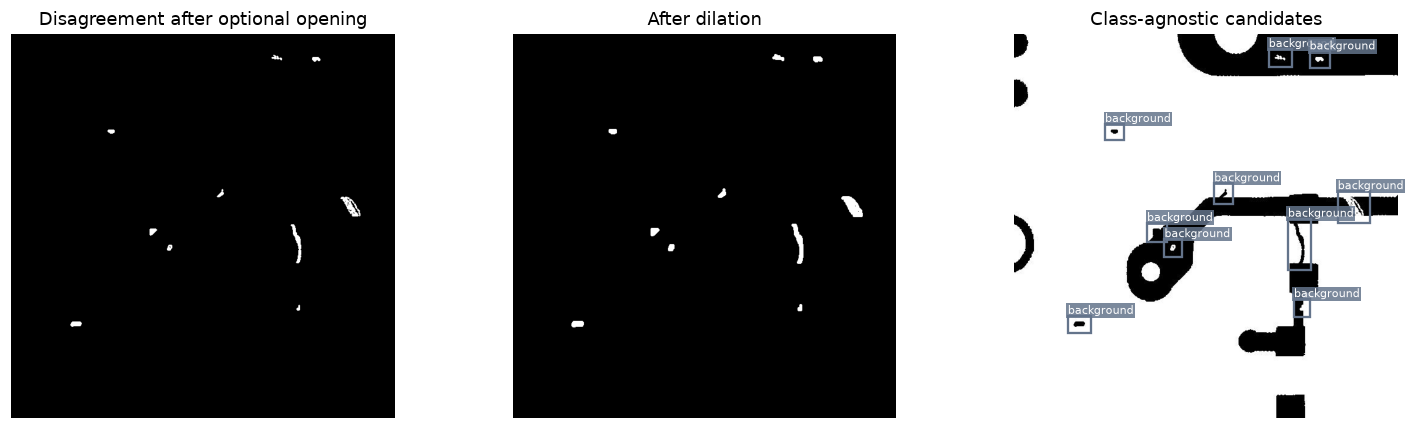

In [9]:
proposal_results = pd.DataFrame([
    proposal_recall(val, dict(min_area=a, dilation=d, pad=9, opening=o))
    for a in [4, 8, 16] for d in [1, 2] for o in [0, 1]
])
proposal_results = proposal_results.sort_values(
    ['recall_at_50', 'proposals_per_image'], ascending=[False, True])
display(proposal_results)
chosen = proposal_results.iloc[0]
CONFIG = {key: int(chosen[key]) for key in ['min_area', 'dilation', 'pad', 'opening']}
proposal_results.to_csv(ARTIFACTS / 'validation_proposals.csv', index=False)
print('Selected using validation only:', CONFIG)
t, s = load_pair(train[0])
boxes, diff, mask = propose(t, s, **CONFIG)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(diff, cmap='gray'); axes[0].set_title('Disagreement after optional opening'); axes[0].axis('off')
axes[1].imshow(mask, cmap='gray'); axes[1].set_title('After dilation'); axes[1].axis('off')
draw_boxes(axes[2], s, boxes, [0]*len(boxes), 'Class-agnostic candidates')
fig.tight_layout(); save_figure(fig, ROOT, '03_proposals.png')

## 5. Learn defect types with HOG and a random forest
Each candidate becomes a feature vector comprising:
- HOG on 32 × 32 crops of the template, inspected image and disagreement mask;
- two 8 × 8 maps preserving the direction of intensity changes;
- seven geometry/occupancy measurements.

A random forest learns **background plus six defect classes**. Training examples come only from training
images: proposals matched to annotations at IoU ≥ 0.33, slightly jittered annotation crops, and background crops.
The 0.33 value here is a *training assignment rule*, separate from the final 0.50 evaluation criterion.
Every inference box is generated from pixels. No ground-truth crop is supplied at inference.

Random-forest vote scores are used for ranking and thresholding; they are **not calibrated probabilities**.
This is classical supervised machine learning, not deep learning. No backpropagation or GPU is needed.

In [10]:
training_start = time.perf_counter()
X_train, y_train = make_training_data(train, CONFIG)
print('Training feature matrix:', X_train.shape)
display(pd.Series(y_train).map(CLASSES).value_counts().rename('training examples'))
model = fit_classifier(X_train, y_train)
training_seconds = time.perf_counter()-training_start
print(f'Feature extraction + training: {training_seconds:.1f} seconds')
val_raw, _ = predict_records(val, model, CONFIG, threshold=0.)
threshold_rows = []
for threshold in [0., .25, .35, .45, .55, .65]:
    _, result = score_predictions(val, threshold_predictions(val_raw, threshold), .5)
    threshold_rows.append(dict(threshold=threshold, **result))
threshold_table = pd.DataFrame(threshold_rows).sort_values(['F1','threshold'], ascending=[False,True])
THRESHOLD = float(threshold_table.iloc[0].threshold)
display(threshold_table)
threshold_table.to_csv(ARTIFACTS / 'validation_thresholds.csv', index=False)
print('Frozen confidence threshold:', THRESHOLD)
joblib.dump(dict(model=model, config=CONFIG, threshold=THRESHOLD,
                 classes=CLASSES, source_commit=SOURCE_COMMIT, versions=versions),
            ARTIFACTS / 'inspection_model.joblib')

Training feature matrix: (23580, 1107)


background         12726
mousebite           2133
open                1994
spur                1792
pin hole            1670
spurious copper     1653
short               1612
Name: training examples, dtype: int64

Feature extraction + training: 35.7 seconds


,threshold,IoU,precision,recall,F1,mAP,TP,FP,FN,images
0,0.00,0.5,0.974563,0.901471,0.936593,0.905407,1226,32,134,200
1,0.25,0.5,0.974563,0.901471,0.936593,0.905407,1226,32,134,200
2,0.35,0.5,0.978348,0.897059,0.935942,0.900829,1220,27,140,200
3,0.45,0.5,0.991475,0.855147,0.918279,0.860201,1163,10,197,200
4,0.55,0.5,0.992627,0.791912,0.880982,0.801664,1077,8,283,200
5,0.65,0.5,0.993782,0.705147,0.824946,0.721321,959,6,401,200


Frozen confidence threshold: 0.0


['D:\\Projects\\CVFAI\\artifacts\\inspection_model.joblib']

## 6. Final evaluation on all 500 official test images
**IoU** measures box overlap. A prediction is a true positive only when its class is correct and it matches
an unused ground-truth box above the IoU threshold. Duplicates count as false positives.

- Precision: fraction of predictions that are correct.
- Recall: fraction of real defects found correctly.
- F1: balance between precision and recall.
- mAP: mean all-point interpolated average precision across the six defect classes.

Report **mAP@0.50** using all non-background scores (no operating confidence cutoff), while precision/recall/F1
use the validation-selected cutoff. Also report results at **IoU 0.33** for context. Our evaluator is not the
upstream evaluation script and not COCO mAP; do not claim direct leaderboard comparability.
The official README uses a strict >0.33 match; this implementation uses ≥0.33.

,IoU,precision,recall,F1,mAP,TP,FP,FN,images
0,0.50,0.954992,0.898726,0.926005,0.895993,2822,133,318,500
1,0.33,0.961083,0.904459,0.931911,0.903247,2840,115,300,500


,defect,class_id,ground_truth,TP,FP,FN,precision,recall,F1,AP
0,open,1,659,565,36,94,0.9401,0.8574,0.8968,0.8441
1,short,2,478,393,29,85,0.9313,0.8222,0.8733,0.8079
2,mousebite,3,586,520,32,66,0.9420,0.8874,0.9139,0.8826
3,spur,4,483,433,21,50,0.9537,0.8965,0.9242,0.8926
4,spurious copper,5,464,455,7,9,0.9848,0.9806,0.9827,0.9792
5,pin hole,6,470,456,8,14,0.9828,0.9702,0.9764,0.9697


Clean-image inference (including disk I/O): 32.6 ms/image


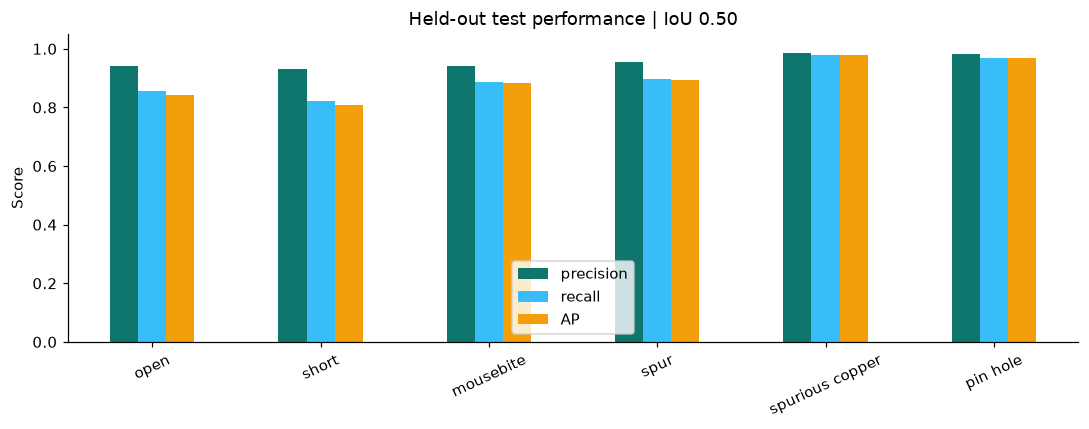

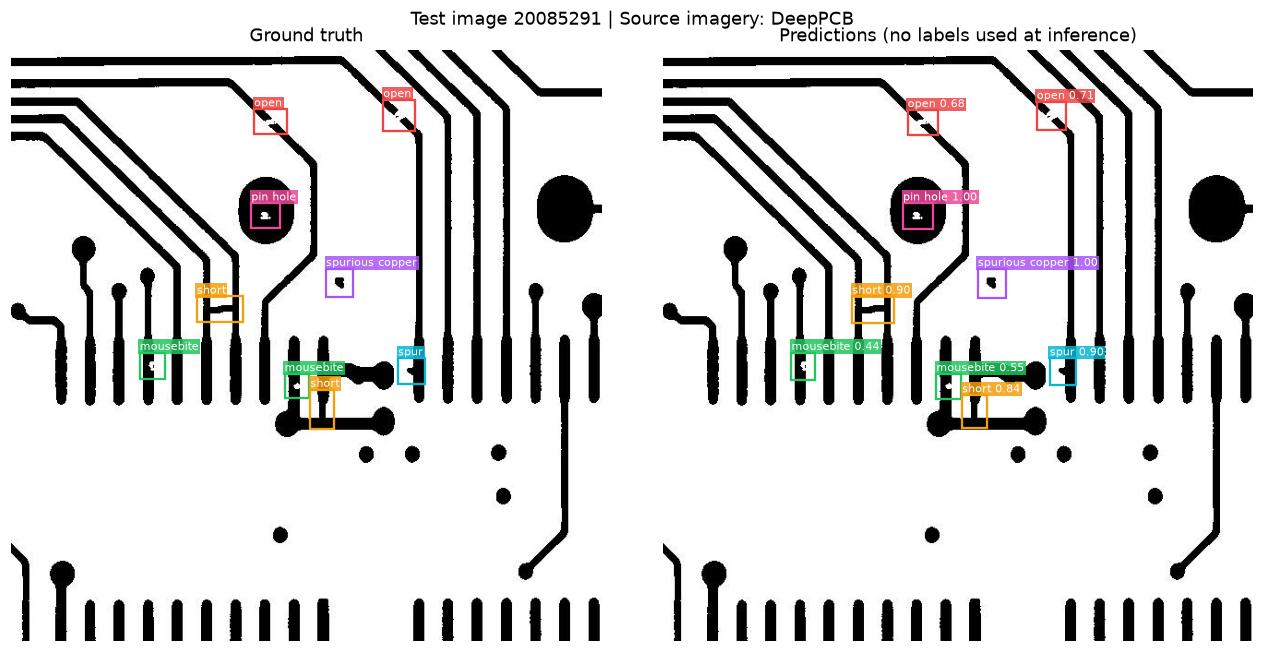

In [11]:
test_raw, test_seconds = predict_records(test, model, CONFIG, threshold=0.)
test_predictions = threshold_predictions(test_raw, THRESHOLD)
per_class, test_metrics = score_predictions(test, test_predictions, .5)
ap_class, ap_metrics = score_predictions(test, test_raw, .5)
per_class['AP'] = ap_class['AP']
test_metrics['mAP'] = ap_metrics['mAP']
_, contextual = score_predictions(test, test_predictions, .33)
_, contextual_ap = score_predictions(test, test_raw, .33)
contextual['mAP'] = contextual_ap['mAP']
display(pd.DataFrame([test_metrics, contextual]))
display(per_class.round(4))
print(f'Clean-image inference (including disk I/O): {1000*test_seconds/len(test):.1f} ms/image')
per_class.to_csv(ARTIFACTS / 'test_per_class.csv', index=False)
(ARTIFACTS / 'test_predictions.json').write_text(json.dumps(test_predictions))
fig, ax = plt.subplots(figsize=(10, 4))
per_class.set_index('defect')[['precision','recall','AP']].plot.bar(ax=ax, color=['#0f766e','#38bdf8','#f59e0b'])
ax.set(ylim=(0,1.05), title='Held-out test performance | IoU 0.50', ylabel='Score', xlabel='')
ax.tick_params(axis='x', rotation=25); fig.tight_layout()
save_figure(fig, ROOT, '04_test_metrics.png')
show_predictions(test[0], test_predictions, ROOT)

## 7. Alignment with ORB / SIFT and RANSAC
The baseline assumes the pair is aligned. A camera shift can turn every track boundary into a false defect.
We estimate a homography from **inspected image to reference image** using descriptor matching, a 0.75 ratio
test and RANSAC. ORB uses Hamming distance; SIFT uses L2 distance. Weak or geometrically implausible fits are
rejected. Newly exposed borders are excluded using a warped validity mask.

Synthetic stress test: sample 30 test images with a fixed seed, then evaluate clean, mild (1° / +3,-2 px)
and moderate (2° / +6,-4 px) conditions. Compare no alignment, ORB and SIFT. No settings are selected from these
test results. Labels stay in reference coordinates because the aim is to restore the reference frame.

**Failed registration remains in the denominator:** its empty detections count as missed defects.
Border defects are retained in ground truth, so crop/visibility loss can also reduce recall.
This controlled experiment tests specific perturbations, not all real camera conditions.

In [12]:
def register_pair(template, tested, method='ORB'):
    """Estimate tested -> template homography, reject unstable geometry, mask borders."""
    detector = (cv2.ORB_create(nfeatures=2500) if method == 'ORB'
                else cv2.SIFT_create(nfeatures=2000))
    kp_t, des_t = detector.detectAndCompute(template, None)
    kp_s, des_s = detector.detectAndCompute(tested, None)
    norm = cv2.NORM_HAMMING if method == 'ORB' else cv2.NORM_L2
    if des_t is None or des_s is None or len(des_t) < 2 or len(des_s) < 4:
        return None, None, dict(success=False, reason='too few descriptors')
    pairs = cv2.BFMatcher(norm).knnMatch(des_s, des_t, k=2)
    good = [m for pair in pairs if len(pair) == 2 for m, n in [pair]
            if m.distance < .75*n.distance]
    if len(good) < 8:
        return None, None, dict(success=False, reason='too few ratio-test matches')
    src = np.float32([kp_s[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_t[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    cv2.setRNGSeed(SEED)
    H, inliers = cv2.findHomography(src, dst, cv2.RANSAC, 3.)
    ratio = float(inliers.mean()) if inliers is not None else 0.
    h, w = template.shape
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    if H is None or not np.isfinite(H).all() or ratio < .3 or inliers.sum() < 8:
        return None, None, dict(success=False, reason='weak RANSAC consensus')
    warped_corners = cv2.perspectiveTransform(corners, H)
    area_ratio = abs(cv2.contourArea(warped_corners))/(w*h)
    if not .6 < area_ratio < 1.5 or not cv2.isContourConvex(warped_corners):
        return None, None, dict(success=False, reason='implausible warp')
    aligned = cv2.warpPerspective(tested, H, (w, h))
    valid = cv2.warpPerspective(np.ones_like(tested), H, (w, h),
                                flags=cv2.INTER_NEAREST) > 0
    valid = cv2.erode(valid.astype(np.uint8), np.ones((7, 7), np.uint8)).astype(bool)
    metadata = dict(success=True, matches=len(good), inlier_ratio=ratio, H=H)
    return aligned, valid, metadata


def perturb_image(image, angle=2., dx=6., dy=-4.):
    h, w = image.shape
    A = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.)
    A[:, 2] += [dx, dy]
    H = np.vstack([A, [0., 0., 1.]])
    return cv2.warpPerspective(image, H, (w, h)), H


def robustness_experiment(records, model, config, threshold, limit=30):
    """Deterministic test subset, untouched selection. Full frames, including edge defects.

    All predictions are evaluated in reference coordinates. Failed registration counts
    as an empty detection set, not as a silently excluded image.
    """
    rng = np.random.default_rng(SEED)
    subset = [records[i] for i in sorted(rng.choice(len(records), min(limit, len(records)), replace=False))]
    conditions = [('clean', 0., 0., 0.), ('mild', 1., 3., -2.), ('moderate', 2., 6., -4.)]
    table, detail = [], []
    for condition, angle, dx, dy in conditions:
        preds = {method: {} for method in ['No alignment', 'ORB + RANSAC', 'SIFT + RANSAC']}
        timings = {method: 0. for method in preds}
        failures = {method: 0 for method in preds}
        errors = {method: [] for method in preds}
        for rec in subset:
            t, s = load_pair(rec)
            shifted, H_forward = perturb_image(s, angle, dx, dy)
            for method in preds:
                start = time.perf_counter()
                if method == 'No alignment':
                    pp = detect(t, shifted, model, config, threshold)
                else:
                    aligned, valid, info = register_pair(t, shifted, method.split()[0])
                    if not info['success']:
                        failures[method] += 1; pp = []
                    else:
                        pp = detect(t, aligned, model, config, threshold, valid)
                        pts = np.float32([[80,80],[560,80],[560,560],[80,560]]).reshape(-1,1,2)
                        reconstructed = cv2.perspectiveTransform(pts, info['H'] @ H_forward)
                        errors[method].append(float(np.linalg.norm(reconstructed-pts, axis=2).mean()))
                timings[method] += time.perf_counter()-start
                preds[method][rec['id']] = pp
        for method in preds:
            _, metrics = score_predictions(subset, preds[method], .5)
            table.append(dict(condition=condition, method=method, **metrics,
                              registration_failures=failures[method],
                              milliseconds_per_image=1000*timings[method]/len(subset),
                              mean_reprojection_error_px=float(np.mean(errors[method])) if errors[method] else None))
        detail.append(dict(condition=condition, predictions=preds))
    return pd.DataFrame(table), [r['id'] for r in subset]

,condition,method,precision,recall,F1,registration_failures,mean_reprojection_error_px,milliseconds_per_image
0,clean,No alignment,0.9767,0.8889,0.9307,0,NaN,32.5297
1,clean,ORB + RANSAC,0.9811,0.8254,0.8966,4,1.3763,69.3296
2,clean,SIFT + RANSAC,0.9699,0.8519,0.9070,3,3.5954,141.4212
3,mild,No alignment,0.8394,0.6085,0.7055,0,NaN,43.1569
4,mild,ORB + RANSAC,0.9814,0.8360,0.9029,4,2.6060,67.7471
5,mild,SIFT + RANSAC,0.9728,0.7566,0.8512,7,3.5507,148.2140
6,moderate,No alignment,0.5234,0.2963,0.3784,0,NaN,39.2026
7,moderate,ORB + RANSAC,0.9474,0.7619,0.8446,6,3.9674,68.0182
8,moderate,SIFT + RANSAC,0.9793,0.7513,0.8503,7,1.8170,148.4777


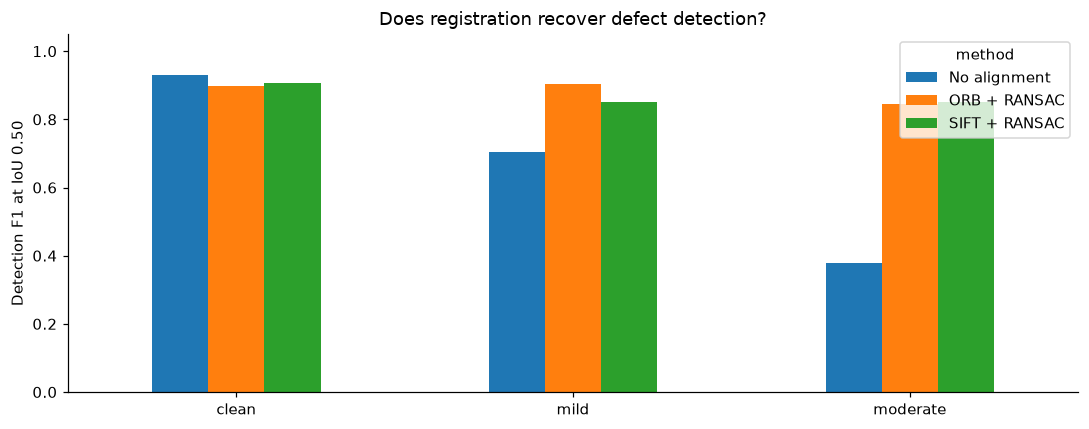

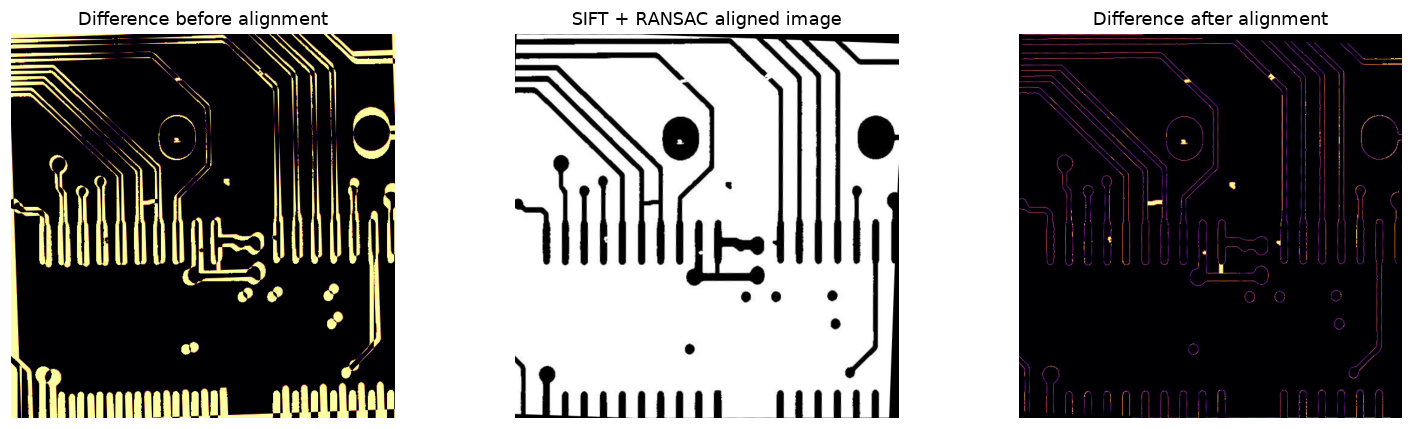

In [13]:
robustness, robustness_ids = robustness_experiment(test, model, CONFIG, THRESHOLD, limit=30)
display(robustness[['condition','method','precision','recall','F1','registration_failures',
                    'mean_reprojection_error_px','milliseconds_per_image']].round(4))
robustness.to_csv(ARTIFACTS / 'robustness.csv', index=False)
(ARTIFACTS / 'robustness_ids.json').write_text(json.dumps(robustness_ids, indent=2))
fig, ax = plt.subplots(figsize=(10,4))
robustness.pivot(index='condition', columns='method', values='F1').reindex(['clean','mild','moderate']).plot.bar(ax=ax)
ax.set(ylim=(0,1.05), ylabel='Detection F1 at IoU 0.50', xlabel='', title='Does registration recover defect detection?')
ax.tick_params(axis='x', rotation=0); fig.tight_layout()
save_figure(fig, ROOT, '06_alignment_robustness.png')
t, s = load_pair(test[0]); moved, _ = perturb_image(s)
aligned, valid, info = register_pair(t, moved, 'SIFT')
fig, axes = plt.subplots(1, 3, figsize=(14,4))
axes[0].imshow(cv2.absdiff(t,moved), cmap='inferno'); axes[0].set_title('Difference before alignment')
if info['success']:
    axes[1].imshow(aligned, cmap='gray'); axes[1].set_title('SIFT + RANSAC aligned image')
    residual = cv2.absdiff(t,aligned); residual[~valid] = 0
    axes[2].imshow(residual, cmap='inferno'); axes[2].set_title('Difference after alignment')
else:
    axes[1].text(.1,.5,'Registration failed'); axes[2].text(.1,.5,info['reason'])
for ax in axes: ax.axis('off')
fig.tight_layout(); save_figure(fig, ROOT, '07_alignment_example.png')

## 8. Honest error analysis
Inspect the weakest test image, selected *after* final evaluation for diagnosis only. Do not tune the model
against this image and then report the same test set as untouched.
The confusion matrix below matches boxes by geometry first and includes an explicit background/missed category.
It therefore reveals classification errors and missed/extra detections, unlike a crop-only accuracy score.

,image,IoU,precision,recall,F1,mAP,TP,FP,FN,images
253,12100011,0.5,0.500000,0.200000,0.285714,0.166667,1,1,4,1
252,12100010,0.5,1.000000,0.200000,0.333333,0.166667,1,0,4,1
179,90100012,0.5,0.285714,0.444444,0.347826,0.416667,4,10,5,1
137,44000030,0.5,0.500000,0.333333,0.400000,0.333333,2,2,4,1
127,44000020,0.5,0.285714,0.888889,0.432432,0.533333,8,20,1,1


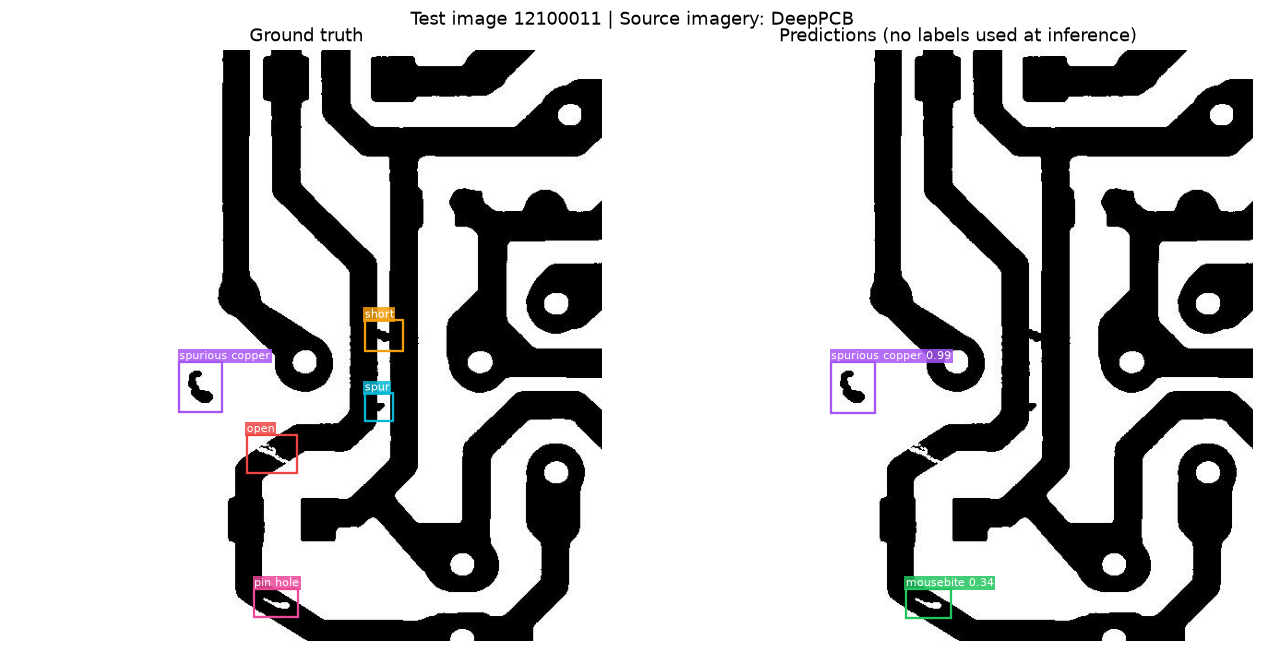

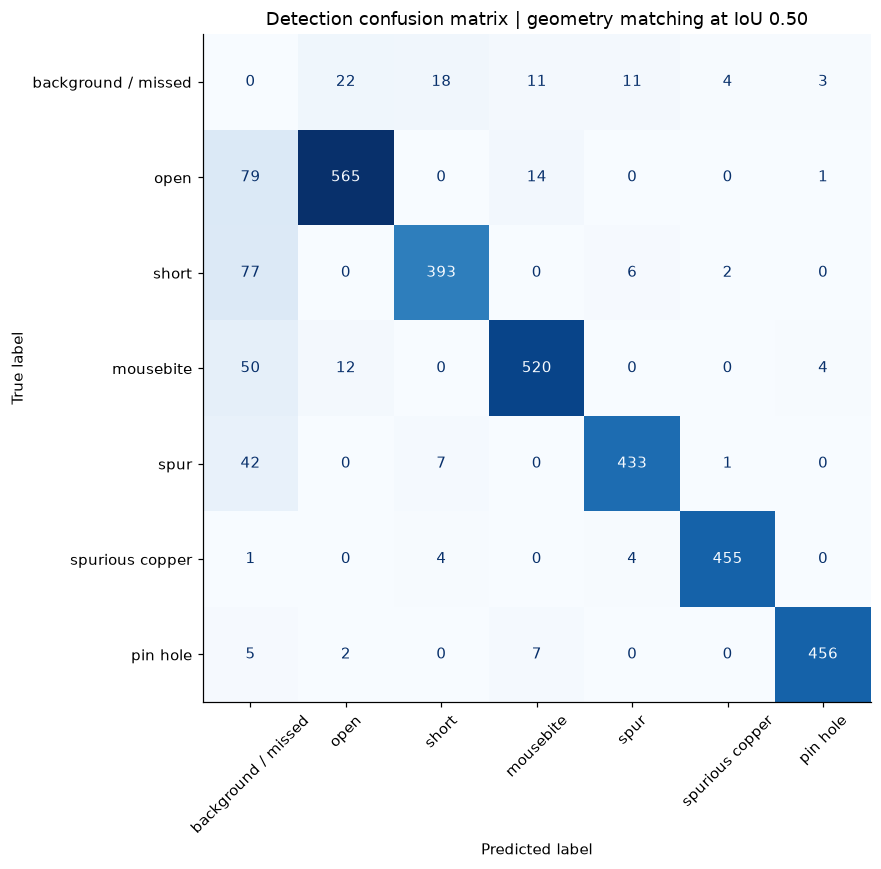

In [14]:
errors = []
y_true, y_pred = [], []
for rec in test:
    gt = ground_truth(rec); pp = test_predictions[rec['id']]
    outcomes, used = match_predictions(pp, gt, .5, class_aware=False)
    used_for_labels = set()
    for pred, matched in outcomes:
        if matched:
            overlaps = box_iou([pred['box']], gt[:,:4])[0]
            eligible = [j for j in range(len(gt)) if j not in used_for_labels]
            j = max(eligible, key=lambda j: overlaps[j]); used_for_labels.add(j)
            y_true.append(int(gt[j,4])); y_pred.append(pred['label'])
        else:
            y_true.append(0); y_pred.append(pred['label'])
    for j in range(len(gt)):
        if j not in used_for_labels:
            y_true.append(int(gt[j,4])); y_pred.append(0)
    _, score = score_predictions([rec], {rec['id']:pp}, .5)
    errors.append(dict(image=rec['id'], **score))
error_table = pd.DataFrame(errors).sort_values(['F1','image'])
error_table.to_csv(ARTIFACTS / 'test_image_errors.csv', index=False)
display(error_table.head(5))
worst = next(r for r in test if r['id'] == error_table.iloc[0].image)
show_predictions(worst, test_predictions, ROOT, '08_failure_case.png')
fig, ax = plt.subplots(figsize=(9,8))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=list(range(7)),
    display_labels=['background / missed']+[CLASSES[c] for c in range(1,7)],
    ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
ax.set_title('Detection confusion matrix | geometry matching at IoU 0.50')
fig.tight_layout(); save_figure(fig, ROOT, '09_confusion_matrix.png')

## 9. Reusable inference and optional interactive demo
Use a matching defect-free template and inspected image. Outputs are in **template coordinates**.
Registration failure is an explicit failure state, never silently interpreted as “no defects”.
An empty successful result means “no accepted detections”, not proof of a defect-free board.
The function takes no ground-truth labels.

The dropdown is optional; GitHub displays saved static outputs, while Jupyter can run the widget.
To inspect your own pair, replace the two paths in `inspect_custom(...)` below.

In [15]:
result = inspect_custom(test[0]['template'], test[0]['test'], model, CONFIG, THRESHOLD, method='SIFT')
print('Inspection status:', result['status'])
display(pd.DataFrame(result['predictions']))
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    choices = widgets.Dropdown(options=[r['id'] for r in test[:20]], description='Test image:')
    output = widgets.Output()
    def preview(change=None):
        rec = next(r for r in test if r['id'] == choices.value)
        with output:
            clear_output(wait=True)
            t, s = load_pair(rec); pp = test_predictions[rec['id']]
            fig, ax = plt.subplots(figsize=(7,7))
            draw_boxes(ax, s, [p['box'] for p in pp], [p['label'] for p in pp], rec['id'])
            plt.show(); plt.close(fig)
    choices.observe(preview, names='value')
    display(choices, output)
except ImportError:
    print('Optional interactive dropdown requires ipywidgets. Static figures remain available.')

Inspection status: ok


,box,label,score
0,"[405, 55, 437, 86]",1,0.641691
1,"[265, 64, 298, 91]",1,0.648130
2,"[260, 165, 289, 193]",6,1.000000
3,"[341, 236, 371, 268]",5,1.000000
4,"[205, 266, 250, 295]",2,0.850004
5,"[138, 328, 165, 358]",3,0.554795
6,"[420, 334, 447, 362]",4,0.792087
7,"[296, 350, 323, 377]",3,0.575958
8,"[324, 373, 351, 409]",2,0.837192


Dropdown(description='Test image:', options=('20085291', '20085292', '20085293', '20085294', '20085295', '2008…

Output()

## 10. Export results and interpret the outcome
The JSON below records the measured results, chosen settings, runtime, versions and source revision.
Model weights stay local because retraining is part of the exercise. Only load joblib files you trust.

### What this project demonstrates
- CO1: handcrafted image features and HOG.
- CO2: ORB / SIFT interest points and descriptors.
- CO3: matching, homography and RANSAC.
- CO4: binary segmentation and connected components (not temporal object tracking).
- CO5: **not demonstrated** by this CPU-only classical model; a deep detector is a future extension.

### Limits and next experiments
1. Shared source layouts, artificial defects and preprocessed images limit deployment claims.
2. Proposal recall limits the classifier; merged components can hide multiple defects.
3. Repeated tracks can produce plausible but wrong registration. Current safeguards do not guarantee correctness.
4. New camera/lighting conditions need new data and validation; geometric stress tests alone do not cover them.
5. Future work: group-held-out evaluation, real factory images, controlled lighting tests, then a YOLO comparison
   if the research question requires deep learning. Do not present these as completed experiments.

### Credits
Dataset: Tang et al., *On-line PCB Defect Detector On A New PCB Defect Dataset*,
[paper](https://arxiv.org/abs/1902.06197), [repository](https://github.com/tangsanli5201/DeepPCB).
Methods and software: OpenCV (ORB/SIFT/RANSAC/HOG), scikit-learn (random forest), NumPy, pandas,
Matplotlib, Jupyter and joblib. See `CREDITS.md` for references and software links.
Code and explanatory materials were developed with OpenAI Codex assistance; results are measured by running
this implementation, not copied from the upstream benchmark.

In [16]:
summary = dict(dataset_revision=SOURCE_COMMIT, seed=SEED, versions=versions,
    split_sizes=dict(train=len(train), validation=len(val), test=len(test)),
    proposal_config=CONFIG, confidence_threshold=THRESHOLD,
    training_seconds=training_seconds, test_inference_seconds=test_seconds,
    test_at_50=test_metrics, test_at_33=contextual,
    feature_dimension=int(X_train.shape[1]), training_examples=int(len(y_train)),
    robustness_subset_size=len(robustness_ids),
    evaluation='class-aware one-to-one, all-point AP; not official DeepPCB or COCO evaluator')
(ARTIFACTS / 'results.json').write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
print('Completed: model, metrics, split manifest, predictions and nine figures saved.')

{
  "dataset_revision": "08e98c4db5922613fb97176eb3d6497d48260cb1",
  "seed": 42,
  "versions": {
    "python": "3.12.14",
    "numpy": "2.5.4",
    "pandas": "3.0.1",
    "opencv": "4.11.0",
    "sklearn": "1.9.1",
    "matplotlib": "3.11.2"
  },
  "split_sizes": {
    "train": 800,
    "validation": 200,
    "test": 500
  },
  "proposal_config": {
    "min_area": 8,
    "dilation": 1,
    "pad": 9,
    "opening": 1
  },
  "confidence_threshold": 0.0,
  "training_seconds": 35.6754713000264,
  "test_inference_seconds": 16.293156300205737,
  "test_at_50": {
    "IoU": 0.5,
    "precision": 0.9549915397631134,
    "recall": 0.8987261146496816,
    "F1": 0.9260049220672683,
    "mAP": 0.8959928689429805,
    "TP": 2822,
    "FP": 133,
    "FN": 318,
    "images": 500
  },
  "test_at_33": {
    "IoU": 0.33,
    "precision": 0.961082910321489,
    "recall": 0.9044585987261147,
    "F1": 0.9319114027891715,
    "mAP": 0.9032467067867399,
    "TP": 2840,
    "FP": 115,
    "FN": 300,
    "ima